# Symptom-Based Agent-Based Epidemic Model

**Overview.** Compartmental SIR models give every infected person the same fixed transmission rate (β) and recovery rate (γ). This model recomputes both every day from each agent's current symptoms, which interact as a network. It adds immunity classes, health reserves, stochastic recovery and death, limited hospital capacity, cafeteria contacts and an isolation phase, and simulates three outbreak scenarios.

**Data.** No external dataset. Symptom coefficients (transmissibility β⁺, severity ζ, physiological system, β⁻ flag) and the scenario symptom timelines come from the accompanying report, `docs/symptom_based_epidemic_model_report.pdf` (Table 1 and Tables 2–4).

**Approach.**
- **Symptom-network engine:** each day's symptoms form a graph. Network and synergy scaling give β_SIR; severity synergy gives ζ_net and, through a sigmoid, γ_SIR. Isolation-inducing (β⁻) symptoms override β_SIR with 0.001–0.005.
- **Agents:** 15,000 agents with strong, normal or weak immunity, each with a health reserve of 100–1000 and an immunity-dependent infection risk.
- **Infection:** p = 1 − exp(−β · Nᵢ / dᵢ) over small-world neighbours and cafeteria table-mates.
- **Recovery:** two-step rule. The daily probability 1 − e^(−max(γ, 0.01)) is scaled by immunity and health, and the cumulative γ must pass a random threshold in [1.5, 3.5].
- **Mortality:** health declines with symptom severity and is offset by home, ward or ICU care. Death is a health-dependent daily risk under lethal symptom combinations, or certain once health reaches 0.
- **Hospitals:** a general ward and ICU with triage. On the epidemic day (hospitals full), capacity rises to 120%, a pandemic hospital opens and the contact network splits into isolation groups of 1–3 agents until the normalization day.

**Key results** (15,000 agents, seed 42):
- The engine reproduces every deterministic value in the report's parameter tables.
- **Upper respiratory infection:**
  - R0 starts at 1.607 and peaks at 1.705 on day 4, against ≈1.6 and 1.73 in the report.
  - Infections peak at 9,932 on day 9, and 14,996 agents have recovered by day 30 with no deaths.
- **Lower respiratory infection:** hospitals saturate on day 6, and 4,920 agents die by day 200 (case fatality 42.6%). Kaplan–Meier survival is 0.15 for severe cases versus 1.00 for mild-to-moderate ones.
- **MeV-1-like infection:** no agent recovers and 1,100 of 1,581 infected agents die (69.6%). Transmission stops within the first week, so 89% of the population is never infected.

In [1]:
import random
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from epidemic_abm import SCENARIOS, SimulationConfig, daily_parameters, parameter_table, run_scenario, summarize
from epidemic_abm import plots

pd.set_option("display.precision", 4)
FIGURES = Path("figures")


def show(path):
    display(Image(filename=str(path)))

## 1. Symptom-network parameter engine

For every day of illness, the engine turns the active symptom set into the parameters the agents use. The tables below are the three scenario timelines from the report. Every deterministic column matches the report's Tables 2–4 (checked in `tests/test_symptoms.py`). The `beta_sir` values of rows containing a β⁻ symptom are random draws in [0.001, 0.005], so they differ from the report's draws.

In [2]:
for scenario in SCENARIOS.values():
    print(scenario.name)
    display(parameter_table(daily_parameters(scenario.timeline, random.Random(0))))

Upper respiratory tract infection


,day,symptoms,beta_combined,beta_sir,zeta_raw,zeta_net,gamma_sir
0,0,"Runny Nose, Sneezing, Muscle Pain",1.8000,0.6429,0.988,0.8218,0.4000
1,1,"Runny Nose, Sneezing, Muscle Pain",1.8000,0.6429,0.988,0.8218,0.4000
2,2,"Runny Nose, Sneezing, Muscle Pain",1.8000,0.6429,0.988,0.8218,0.4000
3,3,"Cough, Runny Nose, Fever, Muscle Pain",1.6023,0.6157,1.589,1.2493,0.3000
4,4,"Cough, Runny Nose, Fever, Muscle Pain",1.6023,0.6157,1.589,1.2493,0.3000
5,5,Muscle Pain,0.0000,0.0000,0.350,0.1891,0.6992


Lower respiratory tract infection


,day,symptoms,beta_combined,beta_sir,zeta_raw,zeta_net,gamma_sir
0,0,"Cough, Sneezing, Fever",2.1888,0.6864,1.0920,0.7904,0.4000
1,1,"Cough, Sneezing, Fever",2.1888,0.6864,1.0920,0.7904,0.4000
2,2,"Cough, Sneezing, Fever",2.1888,0.6864,1.0920,0.7904,0.4000
3,3,"Sneezing, Cough",2.0976,0.6772,0.5400,0.3055,0.5934
4,4,"Sneezing, Cough",2.0976,0.6772,0.5400,0.3055,0.5934
5,5,"Sneezing, Cough",2.0976,0.6772,0.5400,0.3055,0.5934
6,6,"Pneumonia, Cough, Sneezing, Muscle Pain, High ...",0.0000,0.0044,3.7336,2.1720,0.0008


MeV-1-like high-lethality infection


,day,symptoms,beta_combined,beta_sir,zeta_raw,zeta_net,gamma_sir
0,0,"Cough, Fever, Runny Nose",1.5696,0.6108,1.0920,0.7904,0.4000
1,1,"Cough, Fever, Runny Nose",1.5696,0.6108,1.0920,0.7904,0.4000
2,2,"High Fever, Muscle Pain",0.0000,0.0044,0.8060,0.7518,0.1967
3,3,"Loss of Consciousness, Fever, Muscle Pain",0.0000,0.0040,1.9314,1.7242,0.0050
4,4,"Coma, Sepsis",0.0000,0.0027,1.9670,1.9283,0.0022


## 2. Simulation setup

All three scenarios use the same population and infrastructure. The report leaves these values to the user, so the defaults below are this implementation's choices. Immunity mixes and simulation lengths follow the report: 30/60/10 over 30 days for the upper respiratory infection and 40/50/10 over 200 days for the lower respiratory infection. The MeV-1-like run uses 150 days, and because its mix isn't stated, it reuses 30/60/10.

In [3]:
config = SimulationConfig()
pd.Series(vars(config), name="value", dtype=object).to_frame()

,value
n_agents,15000
k_neighbors,8
rewire_prob,0.1
initial_infected,0.03
n_tables,500
max_seats,6
hospital_beds,300
icu_share,0.2
pandemic_beds,200
surge_factor,1.2


In [4]:
results = {key: run_scenario(scenario, config) for key, scenario in SCENARIOS.items()}
summaries = {key: summarize(result) for key, result in results.items()}

pd.DataFrame({
    s["scenario"]: {
        "days": s["days"],
        "ever infected": s["ever_infected"],
        "peak infected": s["peak_infected"],
        "peak day": s["peak_day"],
        "final S / I / R / D": " / ".join(f"{s['final'][k]:,}" for k in "SIRD"),
        "case fatality": f"{s['case_fatality']:.1%}",
        "epidemic day": s["epidemic_day"],
        "normalization day": s["normalization_day"],
    }
    for s in summaries.values()
})

,Upper respiratory tract infection,Lower respiratory tract infection,MeV-1-like high-lethality infection
days,30,200,150
ever infected,14997,11539,1581
peak infected,9932,8515,1572
peak day,9,8,4
final S / I / R / D,"3 / 1 / 14,996 / 0","3,461 / 525 / 6,094 / 4,920","13,419 / 481 / 0 / 1,100"
case fatality,0.0%,42.6%,69.6%
epidemic day,None,6,2
normalization day,None,197,127


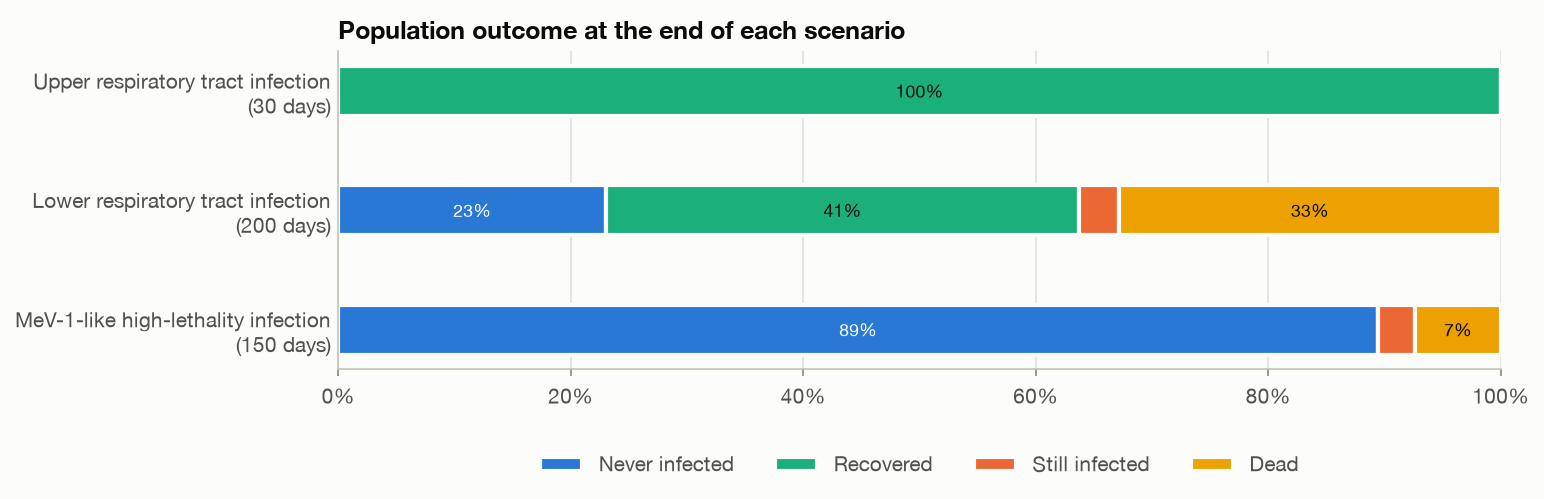

In [5]:
show(plots.plot_outcomes(list(results.values()), FIGURES / "scenario_outcomes.png"))

## 3. Upper respiratory tract infection

Runny nose, sneezing and muscle pain (days 0–2), then cough, runny nose, fever and muscle pain (days 3–4), then muscle pain only. No β⁻ symptom appears, so nobody needs a hospital bed and the epidemic day is never declared.

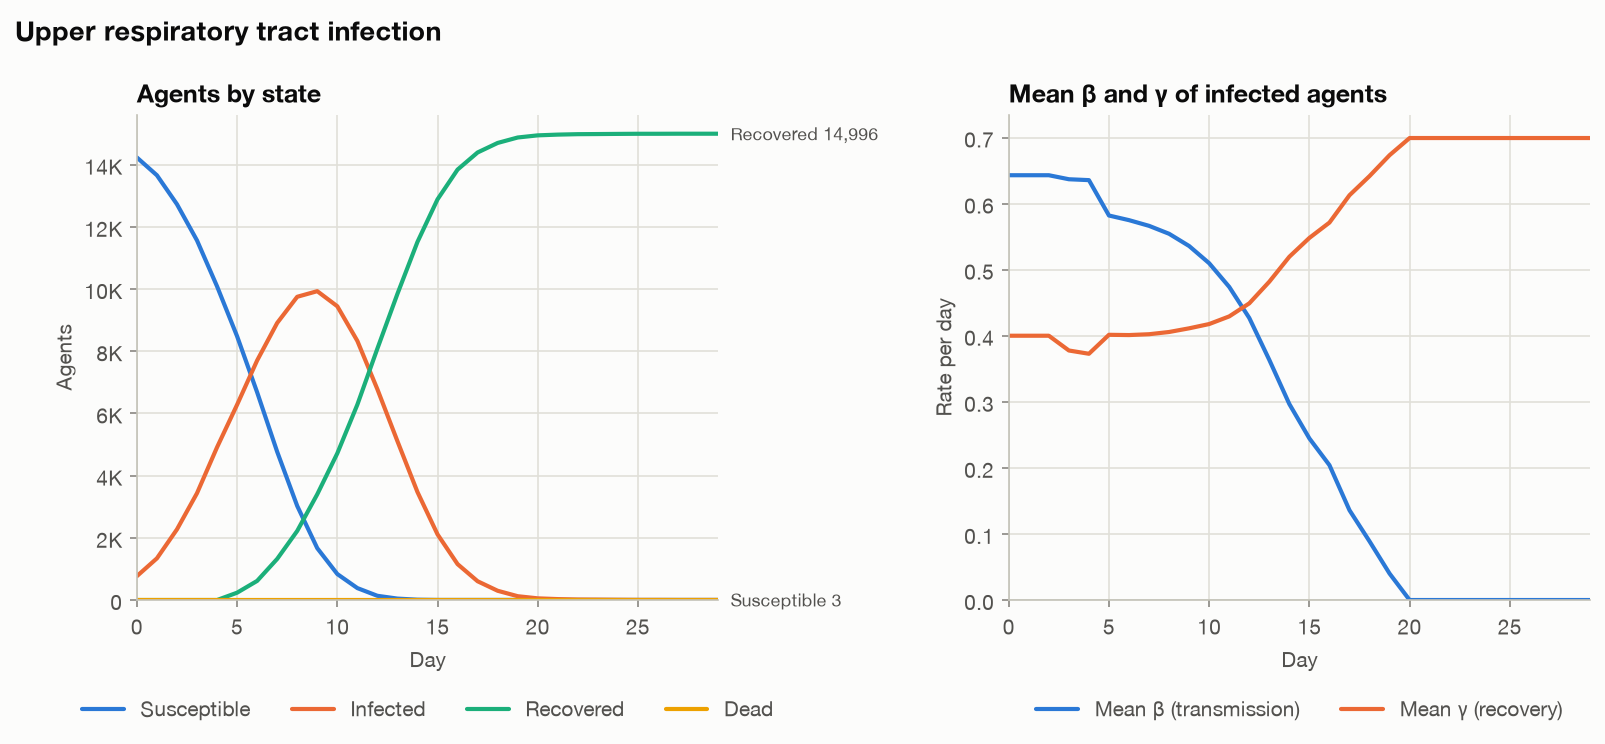

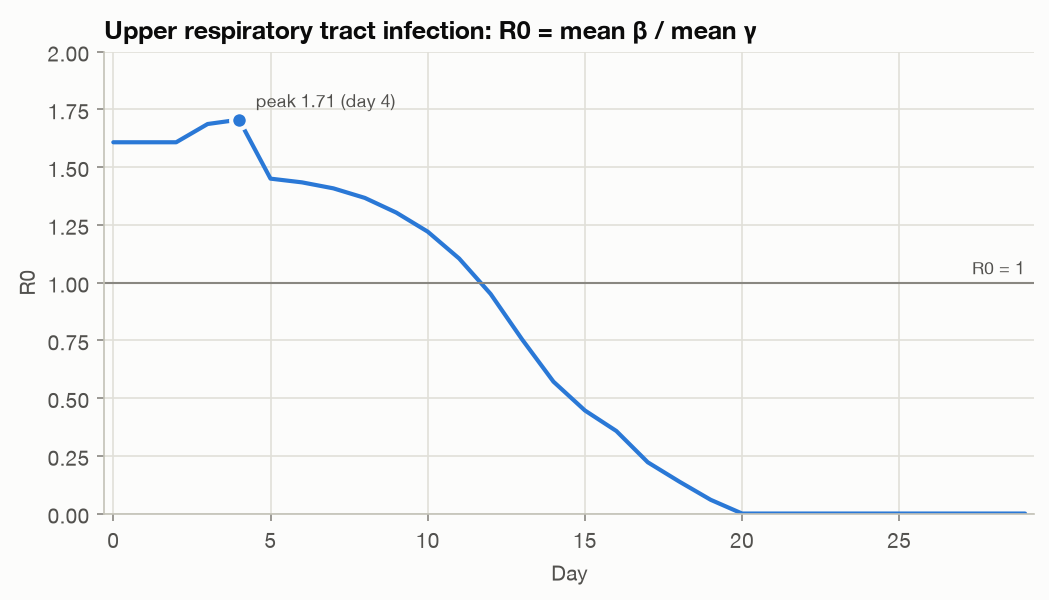

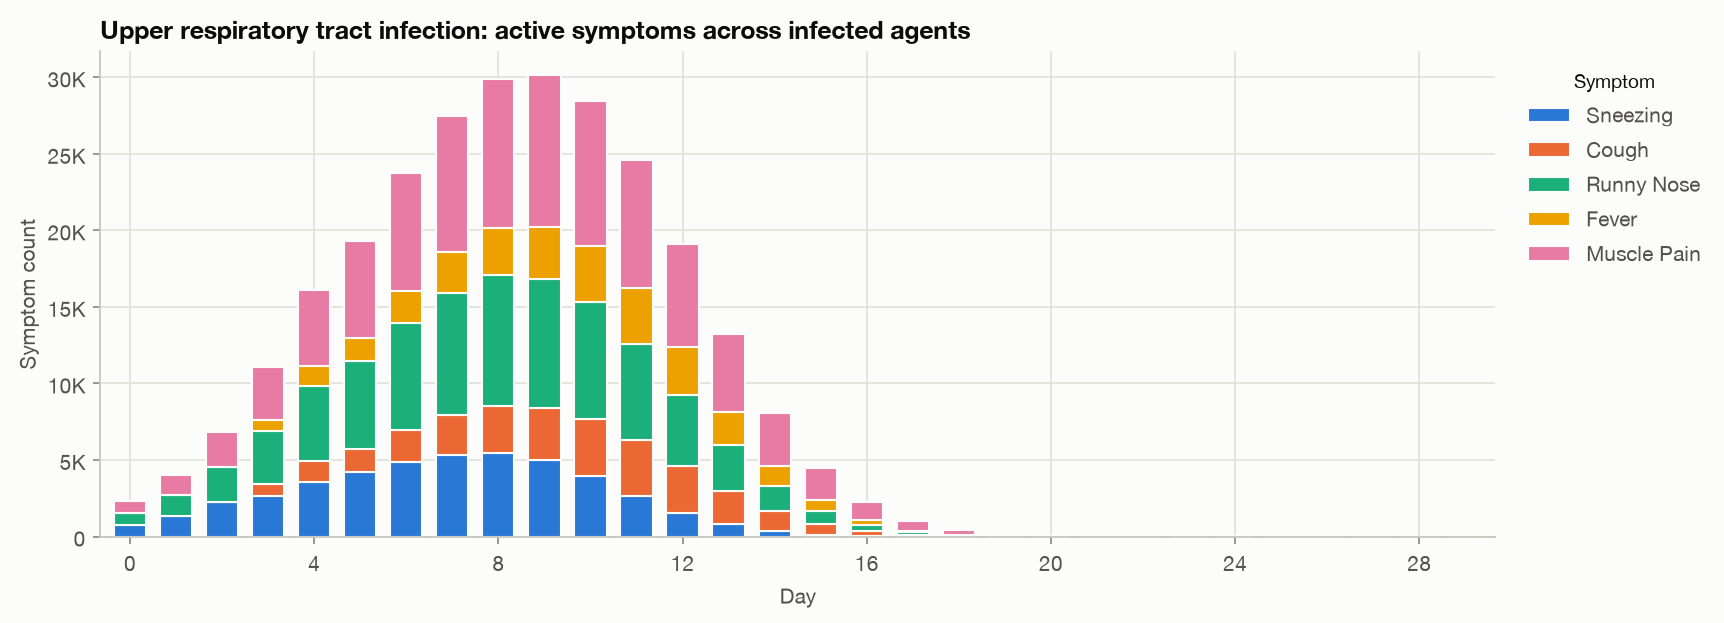

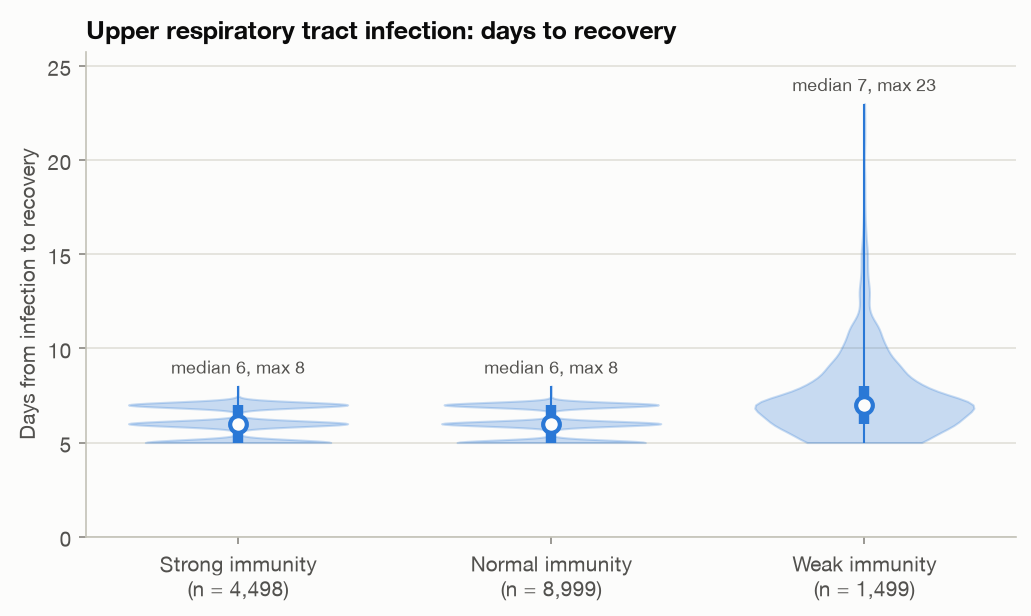

,n,min,q1,median,q3,max
strong,4498.0,5.0,5.0,6.0,7.0,8.0
normal,8999.0,5.0,5.0,6.0,7.0,8.0
weak,1499.0,5.0,6.0,7.0,8.0,23.0


In [6]:
urti = results["urti"]
for path in (plots.plot_sird(urti, FIGURES / "urti_sird.png"),
             plots.plot_r0(urti, FIGURES / "urti_r0.png"),
             plots.plot_symptoms(urti, FIGURES / "urti_symptoms.png"),
             plots.plot_recovery_times(urti, FIGURES / "urti_recovery_times.png")):
    show(path)
pd.DataFrame(summaries["urti"]["recovery_days_by_immunity"]).T

- R0 (mean β / mean γ of infected agents) starts at 1.607, peaks at 1.705 on day 4 and drops below 1 on day 12. This happens as the symptom mix shifts towards muscle pain, which doesn't transmit, and recovery speeds up.
- Infections peak at 9,932 on day 9. By day 30, 14,996 of 15,000 agents have recovered and none have died.
- Recovery takes 5–8 days for strong and normal immunity (median 6), while weak-immunity agents take up to 23 days (median 7).

## 4. Lower respiratory tract infection

Cough, sneezing and fever (days 0–2), then sneezing and cough (days 3–5). From day 6 the profile is pneumonia, cough, sneezing, muscle pain and high fever. Pneumonia and high fever are both β⁻ symptoms, so from day 6 on agents transmit little, recover slowly and face a daily death risk.

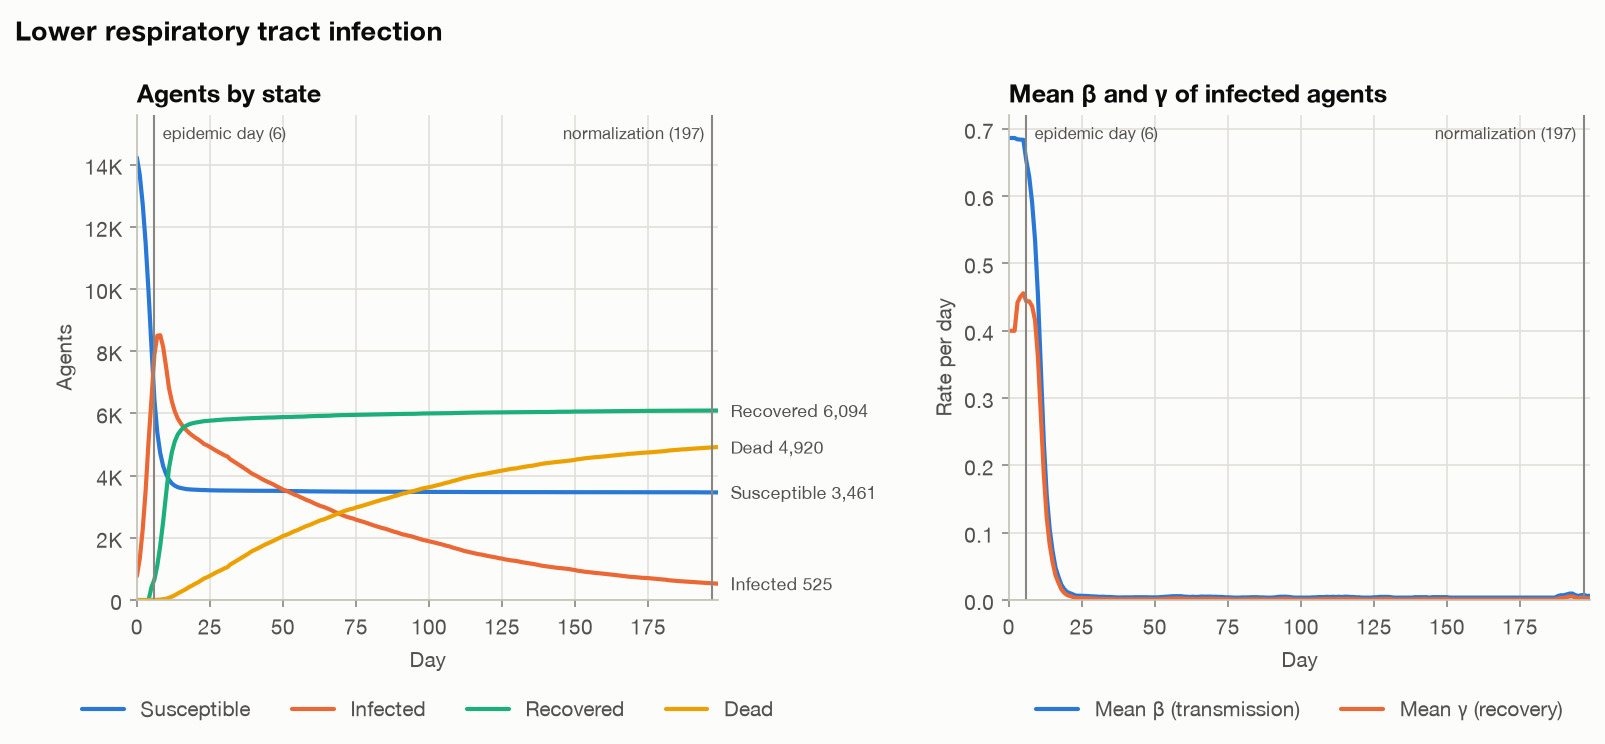

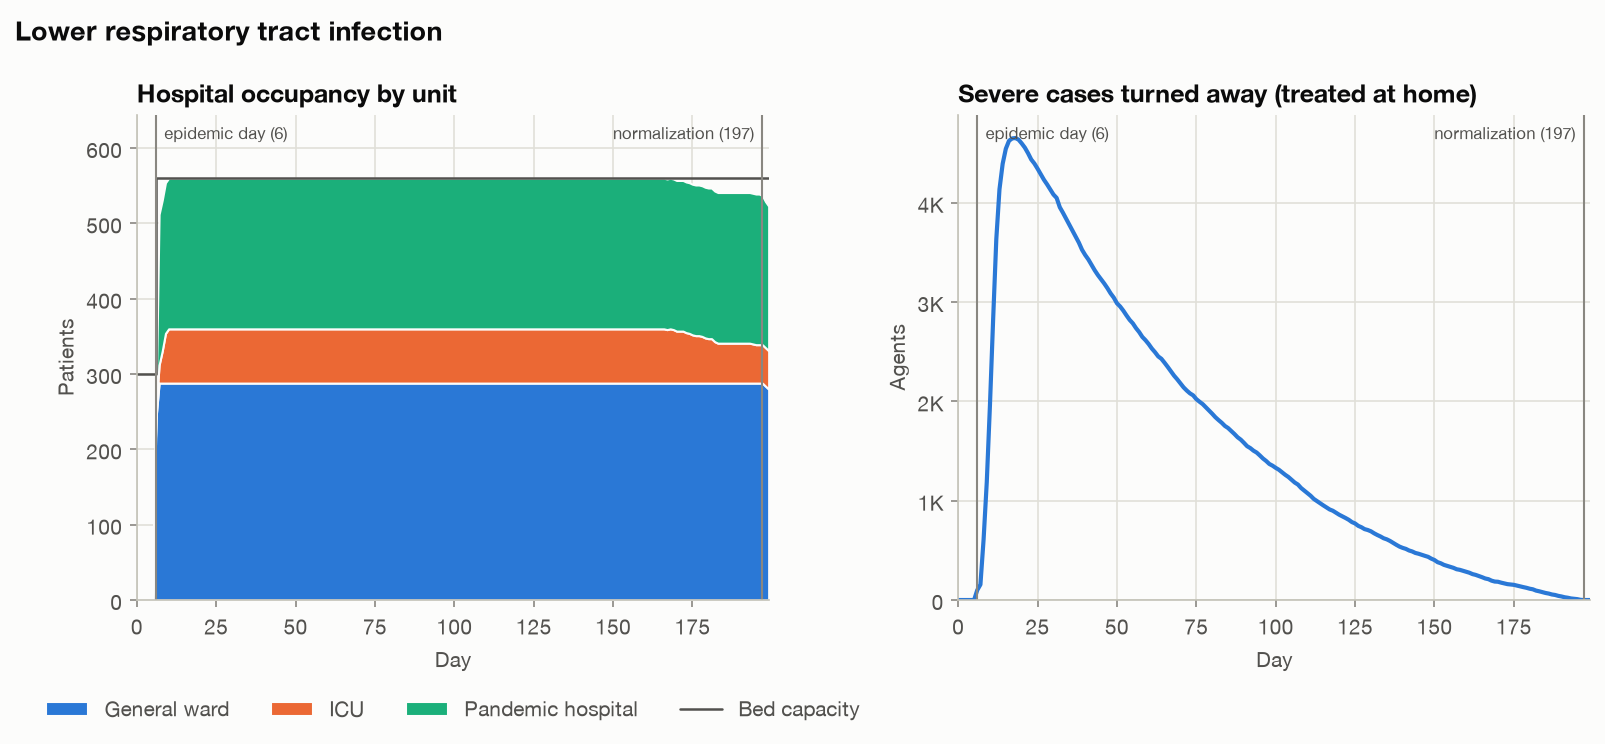

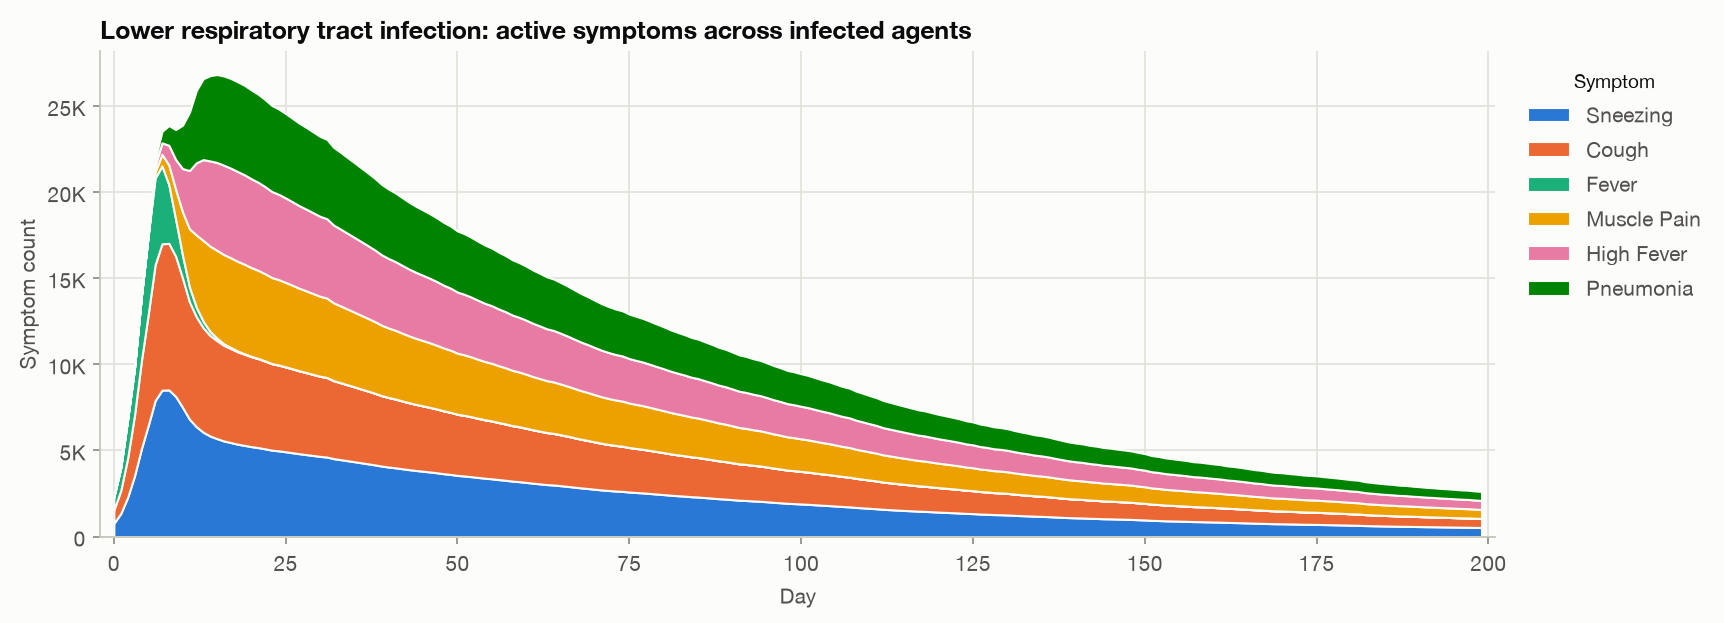

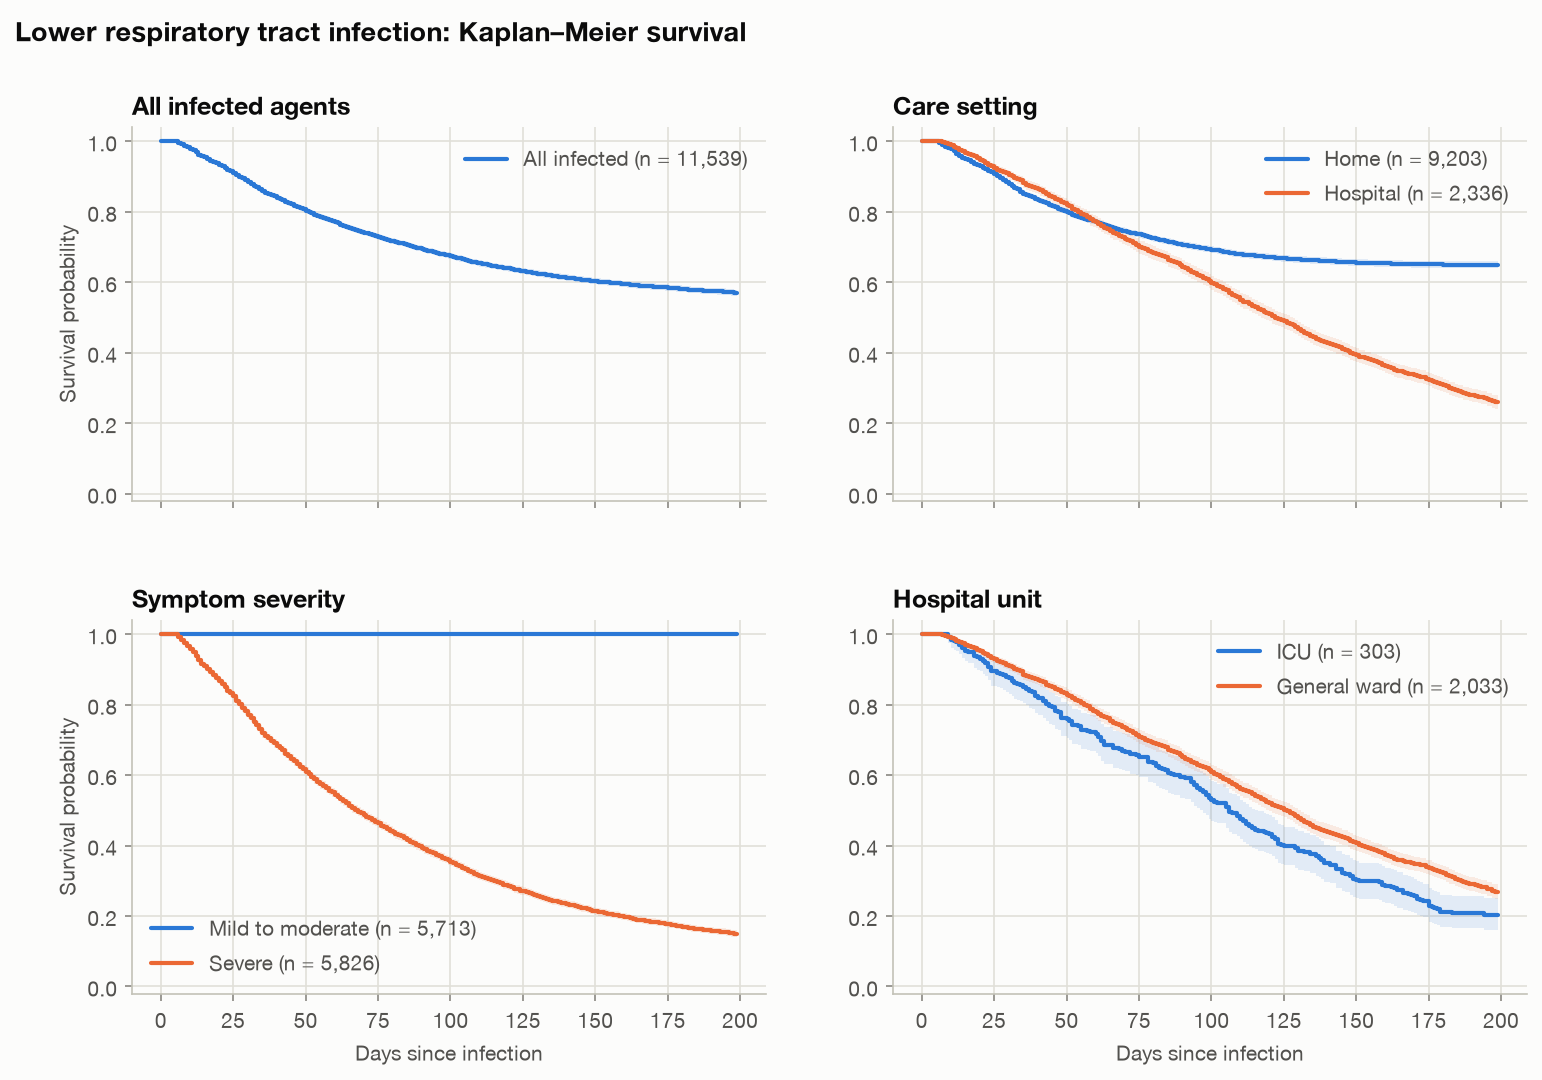

,survival at day 199,agents
all,0.5703,11539
home,0.6500,9203
hospital,0.2603,2336
mild to moderate,1.0000,5713
severe,0.1499,5826
ICU,0.2042,303
general ward,0.2690,2033


In [7]:
lrti = results["lrti"]
for path in (plots.plot_sird(lrti, FIGURES / "lrti_sird.png"),
             plots.plot_hospital(lrti, FIGURES / "lrti_hospital.png"),
             plots.plot_symptoms(lrti, FIGURES / "lrti_symptoms.png"),
             plots.plot_survival(lrti, FIGURES / "lrti_survival.png")):
    show(path)
s = summaries["lrti"]
pd.DataFrame({"survival at day 199": s["survival_at_end"], "agents": s["group_sizes"]})

- Severe cases flood the 300 regular beds on day 6, which becomes the epidemic day. Capacity rises to 360 regular beds plus a 200-bed pandemic hospital, and up to 4,652 severe cases a day are still treated at home.
- The isolation network stops the outbreak: 3,461 agents (23%) are never infected.
- 4,920 agents die by day 200, a case fatality of 42.6%. Fatality falls with immunity: 69.9% for weak, 44.6% for normal and 32.6% for strong immunity.
- **Survival by severity:** agents who never develop β⁻ symptoms all survive, while severe cases reach a survival of 0.15 by day 199 (log-rank p < 0.0001).
- **Survival by care setting:** hospitalized agents fare worse than those at home (0.26 vs 0.65), because only the sickest are admitted. ICU patients fare worst (0.20).

## 5. MeV-1-like high-lethality infection

Cough, fever and runny nose (days 0–1), then high fever and muscle pain (day 2), then loss of consciousness, fever and muscle pain (day 3). From day 4 the profile is coma and sepsis.

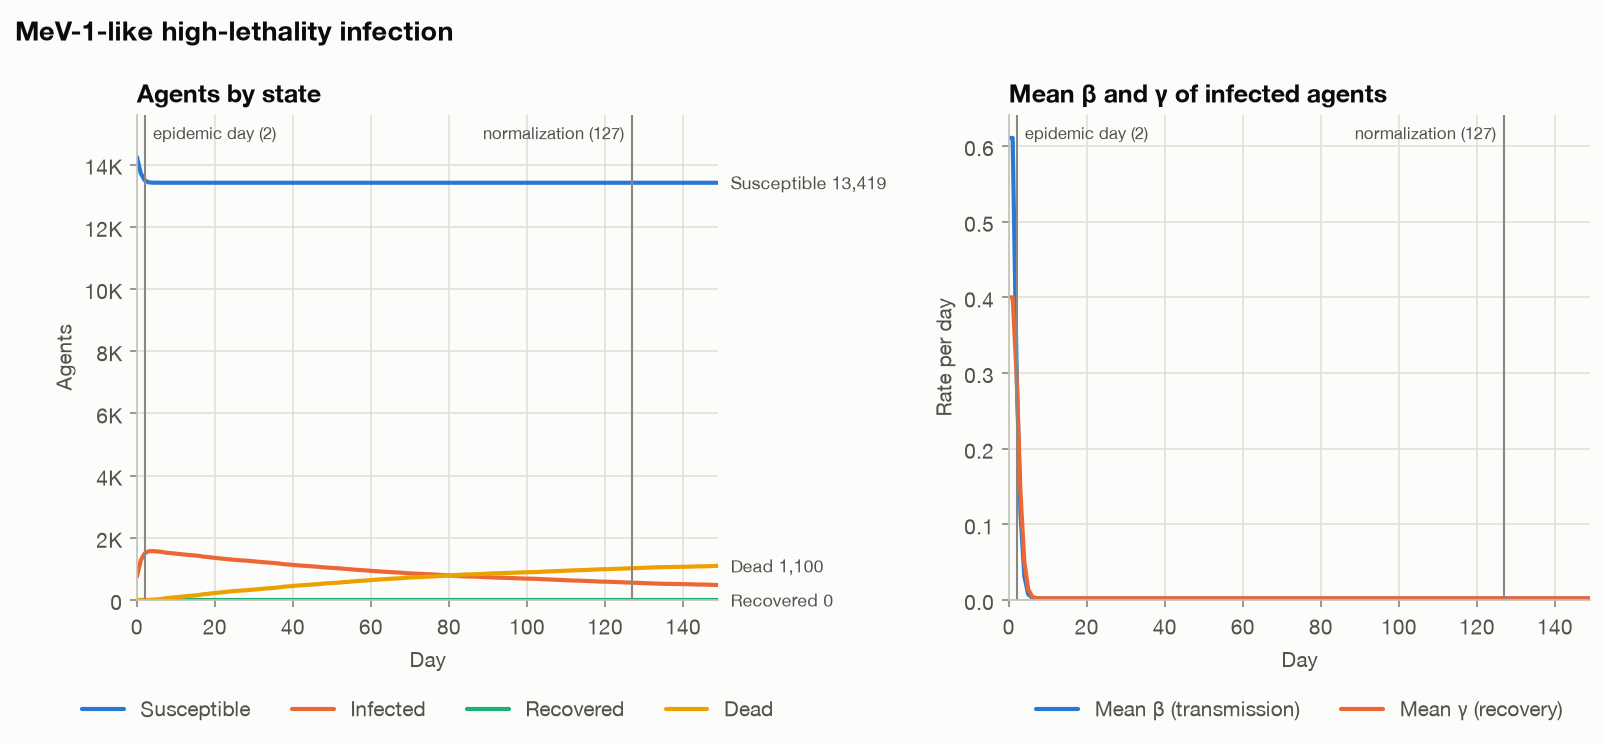

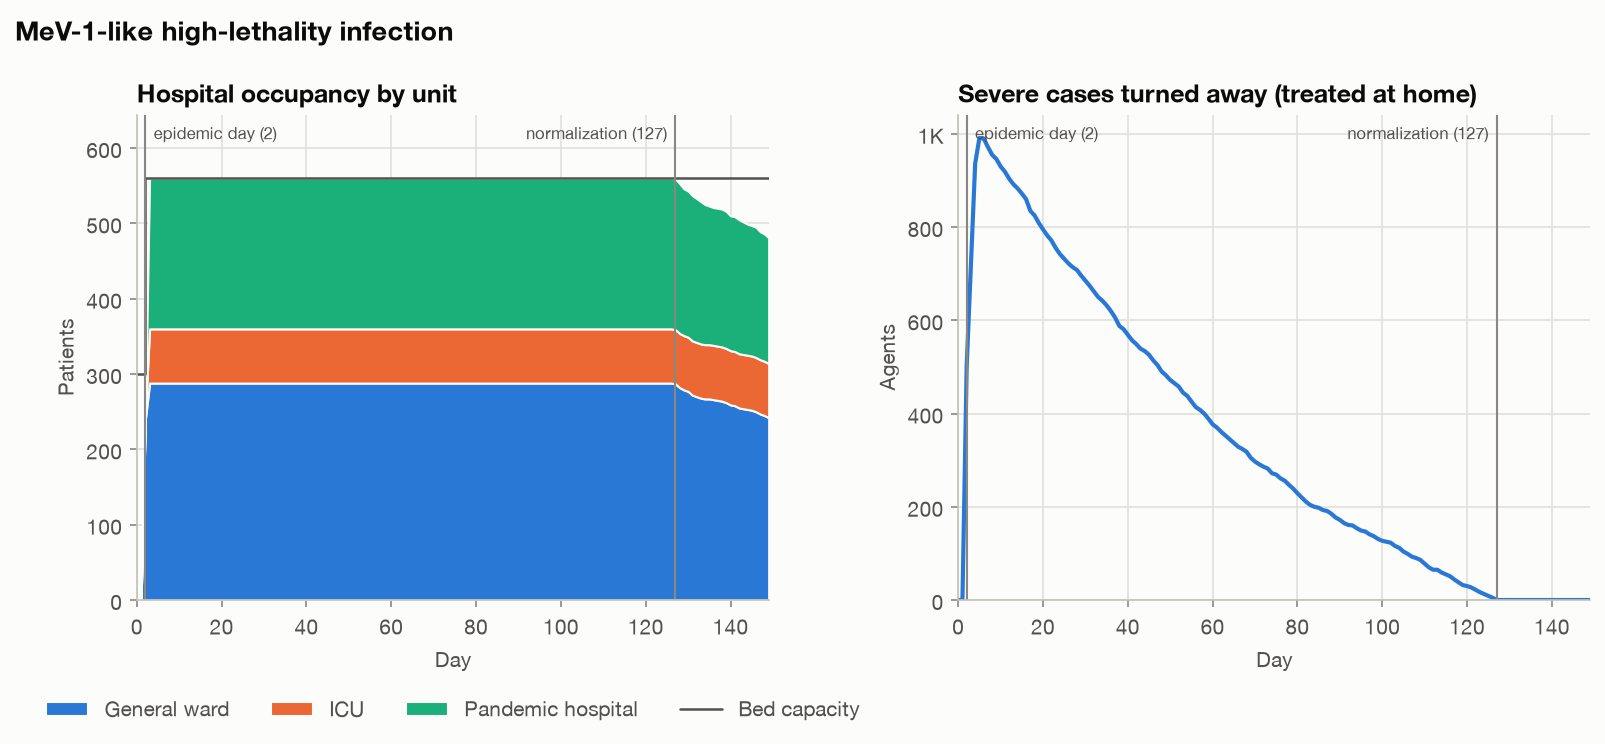

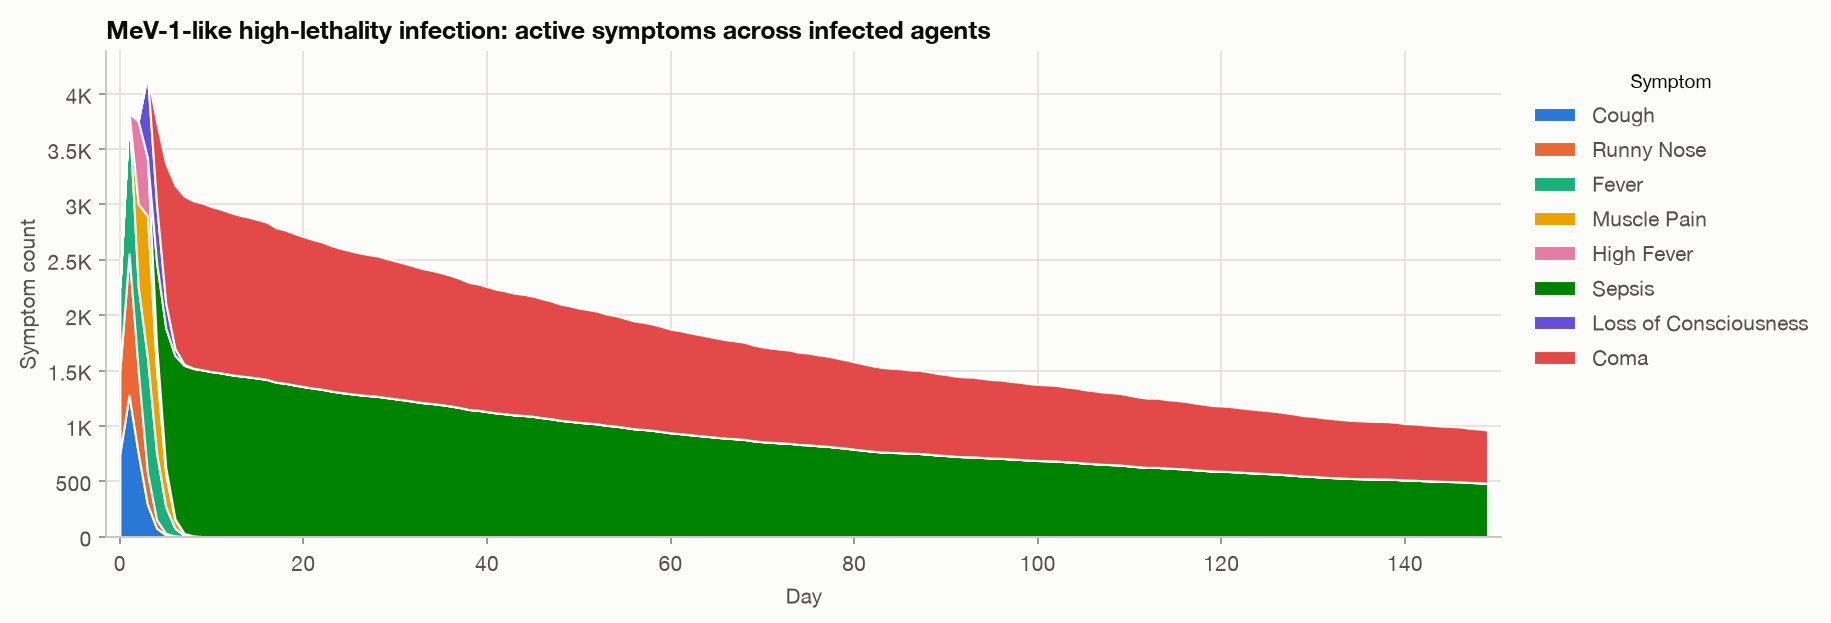

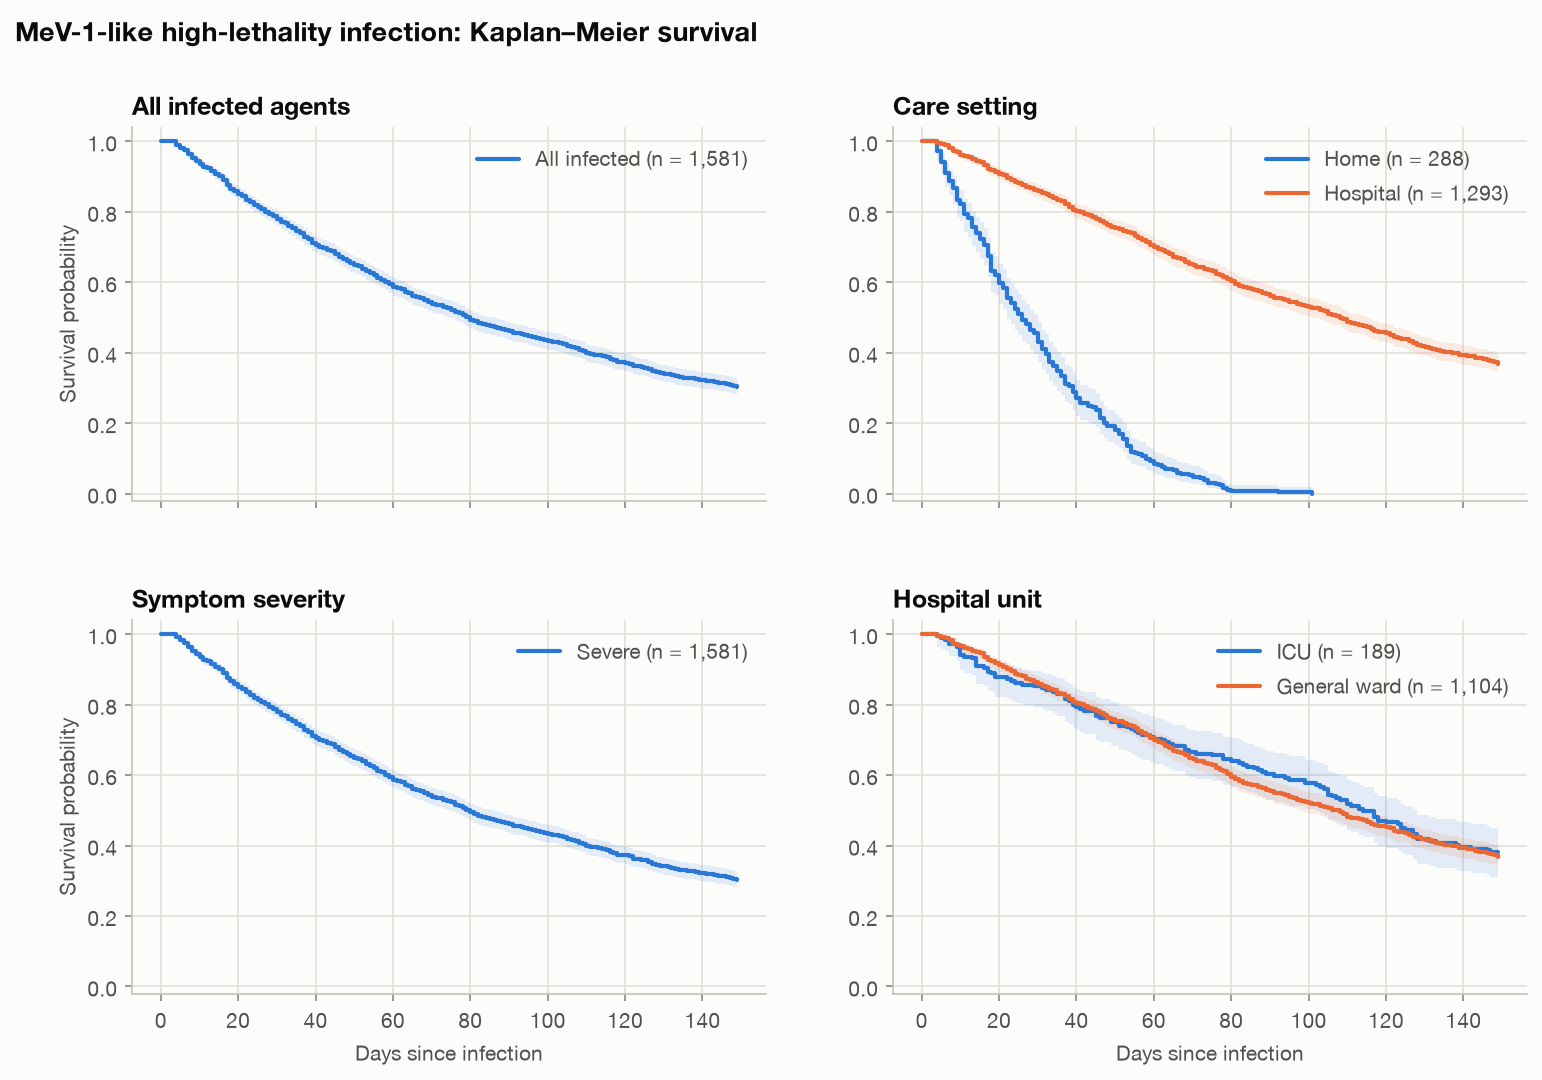

,survival at day 149,agents
all,0.3018,1581
home,0.0000,288
hospital,0.3691,1293
severe,0.3018,1581
ICU,0.3805,189
general ward,0.3669,1104


In [8]:
mev1 = results["mev1"]
for path in (plots.plot_sird(mev1, FIGURES / "mev1_sird.png"),
             plots.plot_hospital(mev1, FIGURES / "mev1_hospital.png"),
             plots.plot_symptoms(mev1, FIGURES / "mev1_symptoms.png"),
             plots.plot_survival(mev1, FIGURES / "mev1_survival.png")):
    show(path)
s = summaries["mev1"]
pd.DataFrame({"survival at day 149": s["survival_at_end"], "agents": s["group_sizes"]})

- Hosts turn severe within two days of infection, so transmission ends almost immediately. Only 1,581 agents (10.5%) are ever infected, and the epidemic day is declared on day 2.
- The cumulative recovery score of an infected agent stays below 1.0, under the minimum recovery threshold of 1.5, so no agent recovers. By day 149, 1,100 have died (69.6%) and 481 remain critically ill.
- Hospital care slows the decline: survival at day 149 is 0.37 for hospitalized agents. The 288 agents who never obtained a bed all died.

## Discussion & Results

- **Symptoms set the transmission regime.** The β⁻ override reproduces the report's central claim. Mild respiratory profiles drive fast spread (β_SIR 0.61–0.69), while severe profiles collapse it to 0.001–0.004 because sick agents isolate.
- **Severity and the recovery threshold shape the tail.** Without β⁻ symptoms, γ has a floor of at least 0.3, so agents clear the recovery threshold within about a week. Under pneumonia or coma, γ falls to 0.0008–0.0022: agents whose cumulative score is still below their threshold barely recover and accumulate deaths for months.
- **Immunity matters most in severe disease.** In the mild scenario immunity only stretches the recovery tail (up to 23 days for weak immunity). In the lower respiratory scenario it separates outcomes sharply: case fatality is 69.9% for weak immunity versus 32.6% for strong.
- **Lethality limits spread.** The MeV-1-like pathogen kills most of the agents it infects, yet reaches only 10.5% of the population, matching the report's argument that a highly lethal, fast-progressing pathogen struggles to sustain a pandemic.
- **Comparison with the report.** The upper respiratory scenario matches the report closely: R0 ≈1.6 rising to 1.71 (vs 1.73) on day 4, and recovery in 5–8 days for strong and normal immunity (report: 5–9). The lower respiratory scenario produces more deaths than the report (4,920 vs ≈2,500 by day 200), because unstated settings — symptom health losses beyond cough and fever, the death-probability scale and hospital capacity — are this implementation's choices. They are listed in `SimulationConfig` and at the top of `epidemic_abm/model.py`.